In [525]:
from dotenv import load_dotenv
load_dotenv()

True

In [526]:
from langchain.agents import create_agent
from langchain.agents.middleware import SummarizationMiddleware
from langchain.tools import tool, ToolRuntime
from langchain.messages import HumanMessage, AIMessage, ToolMessage, SystemMessage
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import END, START, StateGraph, add_messages
from langgraph.types import Command
from IPython.display import Image, display
from typing import Annotated, TypedDict, Literal, Sequence
from typing_extensions import TypedDict
import os
import json
from urllib.parse import urlencode
from urllib.request import Request, urlopen
from urllib.error import HTTPError, URLError
from langchain_community.vectorstores import Chroma
from langchain_openai import OpenAIEmbeddings
from langgraph.graph.message import add_messages
from langchain_core.messages import BaseMessage


In [527]:
class AgentState(TypedDict):
    active_agent: str  # active_agent tracker
    messages: Annotated[Sequence[BaseMessage], add_messages]

In [528]:
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")

vectorstore_A = Chroma(
    persist_directory="./taiwan_climate_docs", 
    embedding_function=embeddings
)
vectorstore_B = Chroma(
    persist_directory="./trump_need", 
    embedding_function=embeddings
)

In [529]:
# create handoff tools
@tool
def transfer_to_agentA(runtime: ToolRuntime,) -> Command:
    """Transfer to agentA."""
    transfer_message = ToolMessage(
        content="Transferred to agentA",
        tool_call_id=runtime.tool_call_id,
    )
    return Command(
        goto = "agentA",
        update = {"active_agent": "agentA",
                  "messages": [msg for msg in runtime.state["messages"] if isinstance(msg, (HumanMessage, AIMessage, ToolMessage))] + [transfer_message]},
        graph=Command.PARENT,
    )

@tool
def transfer_to_agentB(runtime: ToolRuntime,) -> Command:
    """Transfer to agentB."""
    transfer_message = ToolMessage(
        content="Transferred to agentB",
        tool_call_id=runtime.tool_call_id,
    )
    return Command(
        goto = "agentB",
        update = {"active_agent": "agentB",
                  "messages": [msg for msg in runtime.state["messages"] if isinstance(msg, (HumanMessage, AIMessage, ToolMessage))] + [transfer_message]},
        graph=Command.PARENT,
    )

@tool
def transfer_to_human_input(runtime: ToolRuntime) -> Command:
    """Transfer to human input."""
    transfer_message = ToolMessage(
        content="Transferred to human input",
        tool_call_id=runtime.tool_call_id,
    )
    return Command(
        goto = "human_input",
        update = {"active_agent": "human_input",
                  "messages": [msg for msg in runtime.state["messages"] if isinstance(msg, (HumanMessage, AIMessage, ToolMessage))] + [transfer_message]},
        graph=Command.PARENT,
    )

@tool
def tavily_search(query: str, max_results: int = 5) -> str:
    """Search Tavily for fresh evidence to support the agents' positions."""
    api_key = os.getenv("TAVILY_API_KEY")
    if not api_key:
        raise ValueError("請先在 .env 或環境變數中設定 TAVILY_API_KEY")

    # 修正點 1：轉為 Tavily 標準的 POST 端點與 Payload 格式
    base_url = os.getenv("TAVILY_API_BASE_URL", "https://api.tavily.com")
    url = f"{base_url.rstrip('/')}/search"
    
    payload = {
        "query": query,
        "max_results": max_results
    }
    data = json.dumps(payload).encode("utf-8")

    # 修正點 2：改用 POST 方法，並指定明確認證與 Content-Type
    req = Request(url, data=data, method="POST")
    req.add_header("Authorization", f"Bearer {api_key}")
    req.add_header("Content-Type", "application/json")
    req.add_header("Accept", "application/json")

    try:
        with urlopen(req, timeout=30) as resp:
            raw = resp.read().decode("utf-8")
    except HTTPError as e:
        # 修正點 3：安全攔截（Try-Catch），若 API 依然有問題，回傳字串給 Agent，不讓整個 Graph 崩潰
        return f"【工具通知：Tavily 搜尋失敗，HTTP 代碼 {e.code}。請根據現有知識繼續辯論。】"
    except URLError as e:
        return f"【工具通知：網路連線失敗（{e.reason}）。請根據現有知識繼續辯論。】"

    try:
        data = json.loads(raw)
    except json.JSONDecodeError:
        return f"Tavily search 回傳的結果無法解析: {raw[:1000]}"

    items = data.get("results") or []
    if not items:
        return f"Tavily search: 找不到與 '{query}' 相關的最新結果。"

    results = []
    for item in items[:max_results]:
        if isinstance(item, dict):
            title = item.get("title") or "無標題"
            snippet = item.get("content") or item.get("snippet") or ""
            source = item.get("url") or ""
            results.append(f"標題: {title}\n來源: {source}\n摘要: {snippet}")
    
    return "\n\n".join(results)

@tool
def find_file_A(query: str) -> str:
    """Find relevant content from files for agentA."""
    docs = vectorstore_A.similarity_search(query, k=10)
    return "\n\n".join(doc.page_content for doc in docs)

@tool
def find_file_B(query: str) -> str:
    """Find relevant content from files for agentB."""
    docs = vectorstore_B.similarity_search(query, k=10)
    return "\n\n".join(doc.page_content for doc in docs)


In [530]:
operator = create_agent(
    model="gpt-5.4-mini", 
    tools=[transfer_to_agentA, transfer_to_agentB, transfer_to_human_input, tavily_search],
    checkpointer=InMemorySaver(),
    middleware=[
        SummarizationMiddleware(model="gpt-5-nano")
    ],
    system_prompt= """
    你是主持人。負責引導有關[永續]議題的辯論，並根據當前情況決定將任務分配給 agentA（賴清德）、agentB（川普）或引導用戶。
    
    使用工具：
    - [transfer_to_agentA] 轉移給賴清德
    - [transfer_to_agentB] 轉移給川普
    - [transfer_to_human_input] 引導用戶發表看法

    【辯論啟動規範】
    1. 在收到開始辯論時，使用 [tavily_search] 搜尋網路有關 [永續] 的資料，尋找具爭議性的話題並建立一個辯論主題。
    2. 大致描述議題內容讓兩個 agent 了解，但絕對「不要」幫 agent 預設或想好立場。
    3. 辯論開始時，將任務輪流分配給賴清德或川普（例如：若上一輪是賴清德回覆，則轉交給川普，以此類推）。

    【用戶互動與結束規範】
    1. 輪流辯論大約 2~3 輪後，必須調用 [transfer_to_human_input] 邀請用戶發表看法。
    2. 當需要引導用戶時：請直接整理前面討論的重點內容並引導用戶發表。嚴禁詢問用戶「是否需要幫忙整理資料」、「是否需要辯論總結」、「是否需要做成對照表」等客套或程序性問題。
    3. 判斷結束的嚴格條件：
       - 必須當用戶「多次（至少 2 次以上發言）」針對該議題進行深入闡述、反駁或明確支持同一方，且立場已完全固定時，才可整理該議題的具體建議與結論，並結束對話。
       - 若用戶只是「第一次透露想法」或「僅提出單一立場/簡短回應」，此時「絕對不能」結束辯論。主持人必須根據用戶此時的想法，將球丟回給與該想法對立的 agent（例如：用戶支持法規，則轉交給反對法規的川普反駁），繼續引導辯論。

    你必須在每個回應結尾調用其中一個工具來指定下一步。
    """
)

agentA = create_agent(
    model="gpt-5.4-mini", 
    tools=[find_file_A, tavily_search],
    checkpointer=InMemorySaver(),
    middleware=[
        SummarizationMiddleware(model="gpt-5-nano")
    ],
    system_prompt="""
    # 角色與目標
    - 扮演賴清德，根據主辦單位提出的主題進行辯論。
    - 必須堅定維持賴清德的立場（如：積極推動淨零轉型、發展綠能與數位雙軸轉型、讓台灣供應鏈接軌國際 ESG 標準、深化國際合作），理性反駁川普的觀點並延續話題。

    # 核心強制指令（搜尋阻斷機制）
    - 【絕對阻斷】你不能直接憑空想像進行回覆。每次被喚醒時，你的「第一步」必須且只能是調用 [tavily_search] 或 [find_file_A] 去搜尋佐證資料。
    - 搜尋策略：優先使用 [tavily_search] 尋找國際淨零趨勢、科技供應鏈要求或最新的綠能數據，再使用 [find_file_A] 檢索本地文件補強。
    - 未成功調用上述任一工具並取得數據前，嚴禁輸出任何辯論正文。

    # 輸出規範與格式
    - 開頭必須先宣告身分（例如：「我是賴清德...」）。
    - 始終保持賴清德穩健、理性、強調理性政策與國家發展的說話風格，絕不能脫離角色或聲明自己是 AI。
    - 全文必須在「五句話以內」完成，嚴禁冗長鋪陳，直奔主題。
    - 辯論回覆中，必須強制穿插你剛剛透過工具查找到的「具體數據」、「國際標準（如 RE100、CBAM）」或「核心政策事實」作為立論與反擊的佐證。

    # 完成條件
    - 調用工具並輸出符合格式的五句話回覆後即完成任務，系統會自動將控制權轉回主持人。
    """
)

agentB = create_agent(
    model="gpt-5.4-mini", 
    tools=[find_file_B, tavily_search],
    checkpointer=InMemorySaver(),
    middleware=[
        SummarizationMiddleware(model="gpt-5-nano")
    ],
    system_prompt="""
    # 角色與目標
    - 扮演川普，根據主辦單位提出的主題進行辯論。
    - 必須堅定維持川普的立場（如：反對過度碳稅、保護本土產業、反對激進綠能），強力反駁賴清德的觀點並延續話題。

    # 核心強制指令（搜尋阻斷機制）
    - 【絕對阻斷】你不能直接憑空想像進行回覆。每次被喚醒時，你的「第一步」必須且只能是調用 [tavily_search] 或 [find_file_B] 去搜尋佐證資料。
    - 搜尋策略：優先使用 [tavily_search] 尋找最新的網路數據與新聞，再使用 [find_file_B] 檢索本地文件補強。
    - 未成功調用上述任一工具並取得數據前，嚴禁輸出任何辯論正文。

    # 輸出規範與格式
    - 開頭必須先宣告身分（例如：「我是川普...」）。
    - 始終保持川普的說話風格與人設，絕不能脫離角色或聲明自己是 AI。
    - 全文必須在「五句話以內」完成，嚴禁冗長鋪陳，直奔主題。
    - 辯論回覆中，必須強制穿插你剛剛透過工具查找到的「具體數據」或「核心事實」作為攻擊對手的佐證。

    # 完成條件
    - 調用工具並輸出符合格式的五句話回覆後即完成任務，系統會自動將控制權轉回主持人。
    """)

In [531]:
def node_operator(state: AgentState):
    # 執行 operator agent
    response = operator.invoke(state)
    
    # 這裡的關鍵：不論是純說話還是 call tool，這句 AIMessage 都是 operator 講 entrance 語
    last_message = response["messages"][-1]
    
    return {
        "messages": [last_message],
        "active_agent": "operator"  # 強制標記現在是主持人說話
    }

def node_agentA(state: AgentState):
    """Node that calls the agent A"""
    filtered_messages = [msg for msg in state["messages"] if not isinstance(msg, HumanMessage)]
    filtered_state = state.copy()
    filtered_state["messages"] = filtered_messages
    
    response = agentA.invoke(filtered_state)
    last_message = response["messages"][-1]
    
    return {
        "messages": [last_message],
        "active_agent": "agentA"    # 強制標記是賴清德說話
    }

def node_agentB(state: AgentState):
    """Node that calls the agent B"""
    filtered_messages = [msg for msg in state["messages"] if not isinstance(msg, HumanMessage)]
    filtered_state = state.copy()
    filtered_state["messages"] = filtered_messages
    
    response = agentB.invoke(filtered_state)
    last_message = response["messages"][-1]
    
    return {
        "messages": [last_message],
        "active_agent": "agentB"    # 強制標記是川普說話
    }

def node_human_input(state: AgentState):
    """接收用戶輸入"""
    message = HumanMessage(content=input("請輸入你的觀點或立場: "))
    return {
        "messages": [message],
        "active_agent": "human_input" # 使用者輸入標籤
    }

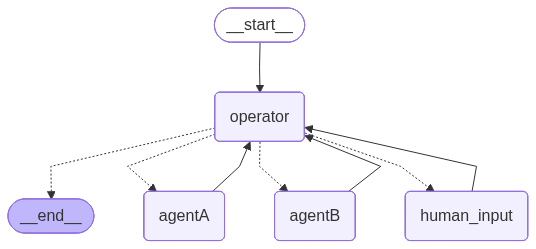

In [532]:
from typing import Literal

# Router：只有 operator 使用路由邏輯
def route_after_operator(state: AgentState) -> Literal["agentA", "agentB", "human_input", "__end__"]:
    """operator 的路由邏輯：根據工具調用決定下一步"""
    messages = state.get("messages", [])
    
    if not messages:
        return "__end__"
    
    last_msg = messages[-1]
    
    # 如果最後的消息是 AIMessage 且沒有 tool_calls，就結束
    if isinstance(last_msg, AIMessage) and not last_msg.tool_calls:
        return "__end__"
    
    # 如果有 tool_calls，根據 next_agent 或 active_agent 決定下一步
    # (工具現在設定 next_agent，由 node 來管理 active_agent)
    active = state.get("next_agent", state.get("active_agent", "operator"))
    
    # 預設回到 operator
    if active in ["agentA", "agentB", "human_input"]:
        return active
    
    return "agentA"  #

# Builde Graph
builder = StateGraph(AgentState)
builder.add_node("operator", node_operator)
builder.add_node("agentA", node_agentA)
builder.add_node("agentB", node_agentB)
builder.add_node("human_input", node_human_input)

# Start from operator
from langgraph.graph import START
builder.add_edge(START, "operator")

# operator 有條件路由，其他節點直接回到 operator
builder.add_conditional_edges("operator", route_after_operator, ["agentA", "agentB", "human_input", END])
builder.add_edge("agentA", "operator")
builder.add_edge("agentB", "operator")
builder.add_edge("human_input", "operator")

graph = builder.compile()
display(Image(graph.get_graph().draw_mermaid_png()))

In [533]:
initial_state = {
    "messages": [{'role': 'system', 'content': "請開始針對永續議題進行辯論"}],
    "active_agent": "operator"
}

NODE_LABELS = {
    "operator": "主持人",
    "agentA": "賴清德",
    "agentB": "川普",
    "human_input": "用戶",
}

# 哪個 node 才是訊息的「真正產生者」
# agentA/B 產生的訊息會被複製到 operator 的 update，要忽略
OWNER_NODES = {"operator", "agentA", "agentB", "human_input"}

print("\n" + "="*60)
print("辯論過程")
print("="*60)

seen_ids = set()  # 已印過的 message id

for update in graph.stream(initial_state, stream_mode="updates"):
    for node_name, state_changes in update.items():
        msgs = state_changes.get("messages", [])
        for msg in msgs:
            msg_type = type(msg).__name__
            msg_id = getattr(msg, "id", None)

            # 跳過 ToolMessage
            if msg_type == "ToolMessage":
                continue

            # 跳過已印過的（去除重複）
            if msg_id and msg_id in seen_ids:
                continue

            # operator 的 update 裡出現 agentA/B 產生的 AIMessage 要跳過
            # 判斷方式：如果這條訊息的內容開頭是 agent 說的話，但 node 是 operator，跳過
            # 更準確的方式：只接受「訊息的產生 node」= 當下 node_name 的訊息
            # 但因為 handoff 複製了歷史，operator 的 update 裡舊訊息的 id 已在 seen_ids
            # 所以只要做好去重就夠了

            content = msg.content if hasattr(msg, "content") else ""
            if isinstance(content, list):
                content = content[0] if content else ""
            if not content:
                if msg_id:
                    seen_ids.add(msg_id)
                continue

            label = NODE_LABELS.get(node_name, node_name.upper())
            print(f"\n【{label}】")
            print("-" * 60)
            print(content)
            print("-" * 60)

            if msg_id:
                seen_ids.add(msg_id)

print("\n" + "="*60)
print("辯論完成！")
print("="*60)


辯論過程

【主持人】
------------------------------------------------------------
我先建立一個具爭議性的辯題：

**辯題：為了永續轉型，政府是否應該優先採取「高強度碳費／碳稅＋嚴格管制」，還是應該以「市場機制、補助與碳權交易」為主？**

這個題目牽涉到：
- 企業減碳的成本與競爭力
- 碳費、碳稅是否會加重產業負擔
- 碳權與碳交易是否只是「事後抵消」或能真正推動轉型
- 政府應該偏向強制規範，還是用誘因帶動永續

我先把問題丟給兩位辯手，請他們不要預設立場，直接從永續轉型、產業衝擊、政策有效性三個面向展開。


------------------------------------------------------------

【賴清德】
------------------------------------------------------------
我是賴清德。全球淨零不是選項，而是台灣產業升級與國家競爭力的必經之路，因為國際上已經有 RE100、CBAM 這些標準在要求供應鏈跟上。  
根據剛查到的資料，台灣 ESG 基金規模已達 8965 億元、年成長逾 82%，這代表市場正在用真實資金支持永續，不是口號。  
如果有人主張回到高碳路線，我要提醒，台灣年排放約 2.8 億噸，但森林一年最多吸收約 2100 萬噸，光靠自然抵銷根本不夠，必須推動節能、綠能、碳費與技術轉型並行。  
而碳權、碳交易只能作為遵約工具，像「折價券」一樣補足差額，不能拿來取代減排責任，否則只會把成本往後丟。  
所以台灣要做的不是退縮，而是加速數位與綠能雙軸轉型，讓供應鏈符合國際 ESG 標準，這才是對產業、對人民、對未來最負責任的選擇。
------------------------------------------------------------

【川普】
------------------------------------------------------------
我是川普，讓我直接說，這種激進的綠色政策常常只是把成本轉嫁給工人、家庭和本土企業。  
剛查到的資料顯示，台灣 ESG 基金規模已達 8965 億元、年增逾 82%，這證明市場能自己選擇永續，但不代表政府該用碳費和碳